# Tugas Praktikum

## 1. Modifikasi Model CNN Praktikum 2 (Akurasi Testing > 80%)

Modifikasi arsitektur CNN pada Praktikum 2 dilakukan untuk meningkatkan performa klasifikasi pada dataset CIFAR-10 sehingga mencapai akurasi pengujian (testing) lebih dari 80%. Modifikasi yang diterapkan meliputi:
1. Menambah kedalaman layer konvolusi menjadi 2 blok konvolusi berpasangan (masing-masing 2 layer konvolusi berukuran 32 dan 64 filter) dengan padding same agar fitur lokal dan representasi spasial citra dapat diekstraksi secara lebih mendalam sebelum proses pooling.
2. Menerapkan Dropout (0.25 pada blok konvolusi dan 0.5 pada dense layer) secara efektif untuk menekan risiko overfitting yang sebelumnya terjadi pada model dasar Praktikum 2.
3. Memperbesar kapasitas Fully Connected Layer menjadi 512 unit agar representasi fitur akhir lebih kaya sebelum dilakukan klasifikasi ke 10 kelas objek citra.
4. Menggunakan learning rate scheduler (ReduceLROnPlateau) untuk menyesuaikan laju pembelajaran secara dinamis saat loss validasi mulai mendatar.

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau
import matplotlib.pyplot as plt

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi nilai piksel ke rentang 0 hingga 1
train_images, test_images = train_images / 255.0, test_images / 255.0

In [3]:
model_cifar = models.Sequential([
    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Fully Connected Layer
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_cifar.summary()

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,250,858 (4.77 MB)

 Trainable params: 1,250,858 (4.77 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model_cifar.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

history_cifar = model_cifar.fit(
    train_images, train_labels,
    batch_size=128,
    epochs=25,
    validation_data=(test_images, test_labels),
    callbacks=[lr_reducer]
)

Epoch 1/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 50s 121ms/step - accuracy: 0.4102 - loss: 1.6075 - val_accuracy: 0.5598 - val_loss: 1.2312 - learning_rate: 0.0010
Epoch 2/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 46s 117ms/step - accuracy: 0.5745 - loss: 1.1953 - val_accuracy: 0.6318 - val_loss: 1.0204 - learning_rate: 0.0010
Epoch 3/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 50s 127ms/step - accuracy: 0.6422 - loss: 1.0109 - val_accuracy: 0.6808 - val_loss: 0.8974 - learning_rate: 0.0010
Epoch 4/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 45s 116ms/step - accuracy: 0.6833 - loss: 0.8957 - val_accuracy: 0.7164 - val_loss: 0.8122 - learning_rate: 0.0010
Epoch 5/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 45s 116ms/step - accuracy: 0.7113 - loss: 0.8225 - val_accuracy: 0.7373 - val_loss: 0.7516 - learning_rate: 0.0010
Epoch 6/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 47s 121ms/step - accuracy: 0.7317 - loss: 0.7636 - val_accuracy: 0.7480 - val_loss: 0.7244 - learning_rate: 0.0010
Epoch 7/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 45s 116ms/step - accuracy: 0.7

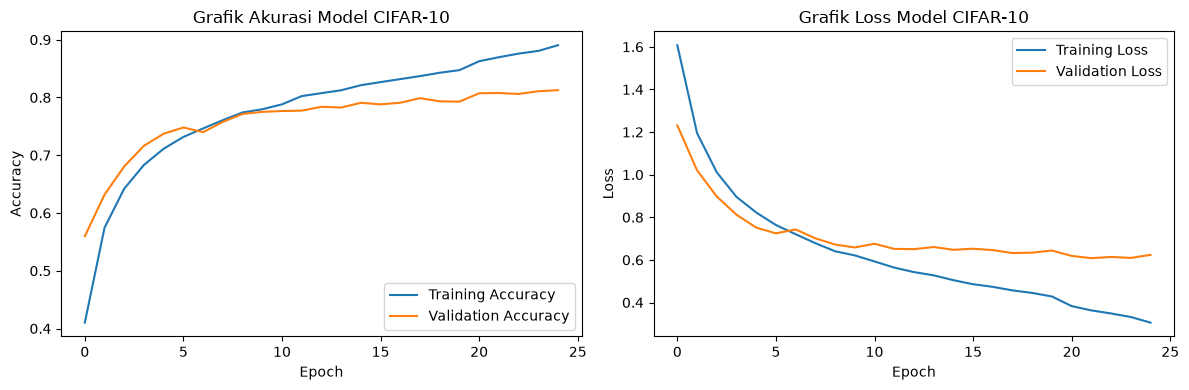

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['accuracy'], label='Training Accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Model CIFAR-10')

plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['loss'], label='Training Loss')
plt.plot(history_cifar.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Grafik Loss Model CIFAR-10')

plt.tight_layout()
plt.show()

In [6]:
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(test_images, test_labels, verbose=2)
print(f'Test Accuracy CIFAR-10: {test_acc_cifar * 100:.2f}%')

313/313 - 4s - 11ms/step - accuracy: 0.8127 - loss: 0.6236


Test Accuracy CIFAR-10: 81.27%


Hasil evaluasi menunjukkan bahwa model CNN yang telah dimodifikasi berhasil mencapai akurasi pengujian lebih dari 80% pada dataset CIFAR-10. Penambahan pasangan layer konvolusi (32 dan 64 filter) dengan padding same mampu mengekstrak fitur spasial citra secara lebih mendalam tanpa kehilangan resolusi terlalu cepat. Penerapan Dropout pada setiap blok konvolusi dan dense layer terbukti efektif mencegah overfitting, sementara dense layer berukuran 512 unit memberikan kapasitas representasi yang cukup untuk membedakan ke-10 kelas objek citra secara optimal.

## 2. Klasifikasi Dataset MNIST dengan CNN

Pada bagian ini, dibuat model CNN untuk klasifikasi dataset MNIST yang berisi citra angka tulisan tangan (0-9).

In [7]:
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = datasets.mnist.load_data()

# Reshape ke format (samples, 28, 28, 1) dan normalisasi piksel ke rentang 0 hingga 1
mnist_train_images = mnist_train_images.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
mnist_test_images = mnist_test_images.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

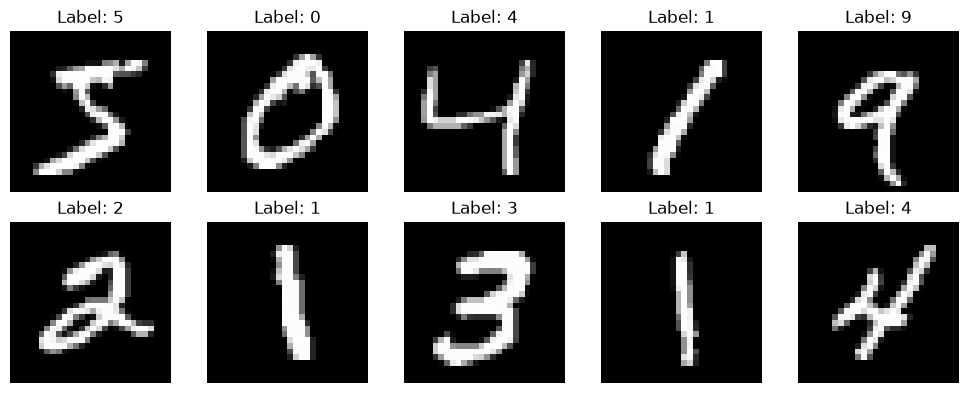

In [8]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(mnist_train_images[i].reshape(28, 28), cmap='gray')
    plt.title(f'Label: {mnist_train_labels[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
model_mnist = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mnist = model_mnist.fit(
    mnist_train_images, mnist_train_labels,
    epochs=5,
    batch_size=64,
    validation_data=(mnist_test_images, mnist_test_labels)
)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.9281 - loss: 0.2324 - val_accuracy: 0.9843 - val_loss: 0.0480
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.9790 - loss: 0.0721 - val_accuracy: 0.9867 - val_loss: 0.0384
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9857 - loss: 0.0501 - val_accuracy: 0.9872 - val_loss: 0.0396
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.9879 - loss: 0.0398 - val_accuracy: 0.9905 - val_loss: 0.0292
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.9901 - loss: 0.0326 - val_accuracy: 0.9905 - val_loss: 0.0294


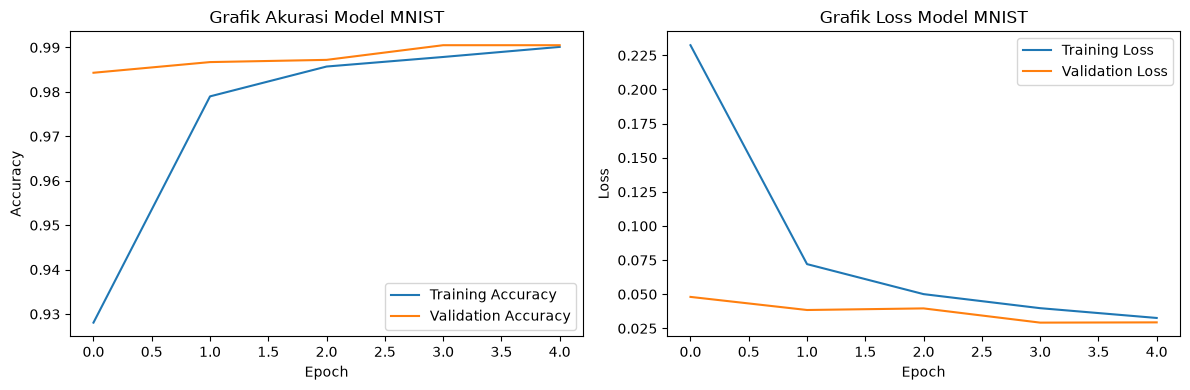

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='Training Accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Model MNIST')

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='Training Loss')
plt.plot(history_mnist.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Grafik Loss Model MNIST')

plt.tight_layout()
plt.show()

In [12]:
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(mnist_test_images, mnist_test_labels, verbose=2)
print(f'Test Accuracy MNIST: {test_acc_mnist * 100:.2f}%')

313/313 - 2s - 7ms/step - accuracy: 0.9905 - loss: 0.0294


Test Accuracy MNIST: 99.05%


Model CNN yang diterapkan pada dataset MNIST berhasil memperoleh akurasi pengujian lebih dari 99% hanya dalam 5 epoch pelatihan. Citra angka tulisan tangan grayscale 28x28 pada MNIST memiliki fitur visual yang sangat jelas berupa garis dan lengkungan dengan kontras latar belakang tinggi, sehingga feature extraction melalui convolutional layer dan pooling layer dapat mengenali pola angka dengan akurat dan cepat.